In [4]:
#imports
#also, unlike the other files, this one is run from the matplotlib directory!
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator
from matplotlib.patches import Rectangle, Ellipse
import pandas as pd
import numpy as np

penglings = pd.read_csv("../penglings.csv")

In [5]:
#constants
width = 1700
height = 1050
marginTop = 50
marginRight = 350
marginBottom = 100
marginLeft = 150
xWidth = width - marginLeft - marginRight
yHeight = height - marginTop - marginBottom

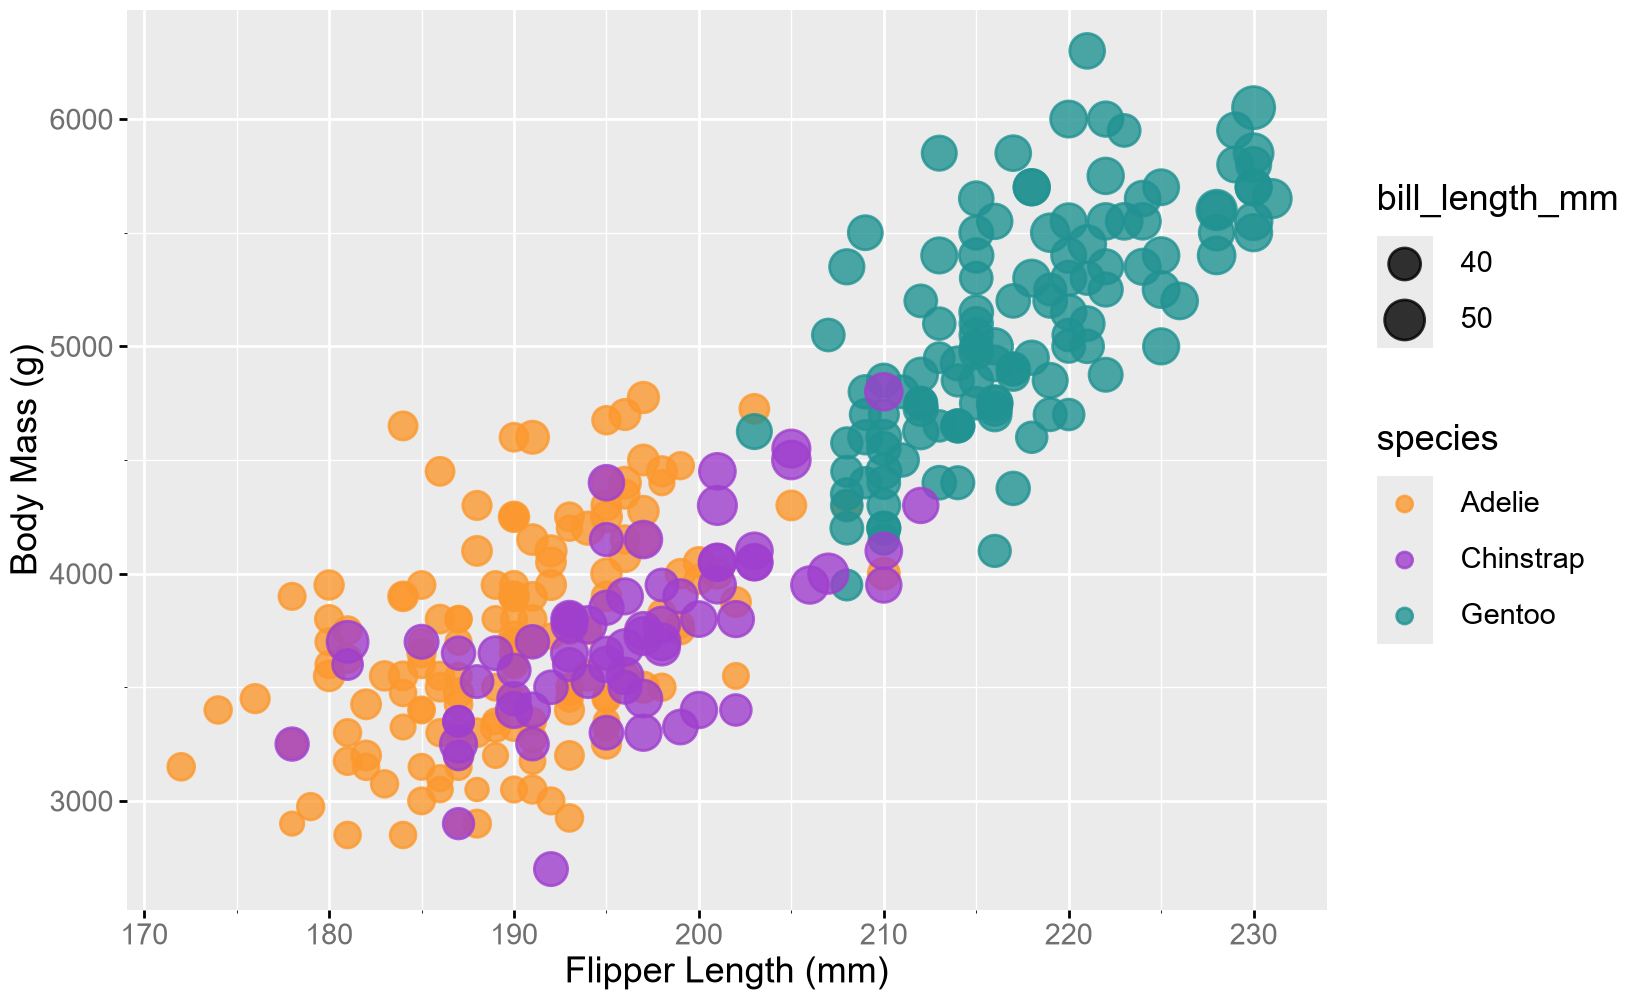

In [12]:
px = 1/plt.rcParams['figure.dpi'] #size of a pixel in inches
figure = plt.figure(figsize=(width*px, height*px))
ax = figure.add_axes([marginLeft/width, marginBottom/height, xWidth/width, yHeight/height])
plt.rcParams['font.family'] = 'Arial' #set global font

#background
ax.set_facecolor("#ebebeb")

#gridlines
ax.set_yticks([3000, 4000, 5000, 6000])
ax.grid(color="white", linewidth=2, which="major")
#divides major gridlines by 2. for some reason it isn't registering this automatically
#so I'm doing it manually here
ax.xaxis.set_minor_locator(AutoMinorLocator(n=2))
ax.yaxis.set_minor_locator(AutoMinorLocator(n=2))
ax.grid(color="white", linewidth=1, which="minor")
ax.set_axisbelow(True) #stops gridlines from displaying over data
ax.spines["top"].set_visible(False) #removes spines
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="both", which="major", labelsize=21, length=6, width=2, labelcolor="#707070")

#axis labels
ax.set_xlabel("Flipper Length (mm)", fontsize=26)
ax.set_ylabel("Body Mass (g)", fontsize=26)

#text in "legend"
figure.text(1400/width, 1 - 250/height, "bill_length_mm", fontsize=26)
figure.text(1400/width, 1 - 490/height, "species", fontsize=26)
square = 56 #same thing as in d3
figure.text((1400 + square * 3/2)/width, 1 - (284 + square/2)/height, "40", fontsize=21)
figure.text((1400 + square * 3/2)/width, 1 - (284 + square * 3/2)/height, "50", fontsize=21)
figure.text((1400 + square * 3/2)/width, 1 - (524 + square/2)/height, "Adelie", fontsize=21)
figure.text((1400 + square * 3/2)/width, 1 - (524 + square * 3/2)/height, "Chinstrap", fontsize=21)
figure.text((1400 + square * 3/2)/width, 1 - (524 + square * 5/2)/height, "Gentoo", fontsize=21)

#shapes in legend
figure.patches.append(Rectangle((1400/width, 1 - (276 + 2 * square)/height), square/width, (2 * square)/height, facecolor="#ebebeb", transform=figure.transFigure))
figure.patches.append(Rectangle((1400/width, 1 - (516 + 3 * square)/height), square/width, (3 * square)/height, facecolor="#ebebeb", transform=figure.transFigure))
figure.patches.append(Ellipse(((1400 + square/2)/width, 1 - (276 + square/2)/height), (0.8 * 40)/width, (0.8 * 40)/height, facecolor="black", alpha=0.8, edgecolor="black", linewidth=2, transform=figure.transFigure))
figure.patches.append(Ellipse(((1400 + square/2)/width, 1 - (276 + square * 3/2)/height), (0.8 * 50)/width, (0.8 * 50)/height, facecolor="black", alpha=0.8, edgecolor="black", linewidth=2, transform=figure.transFigure))
figure.patches.append(Ellipse(((1400 + square/2)/width, 1 - (516 + square/2)/height), 16/width, 16/height, facecolor="#fc992f", alpha=0.8, linewidth=2, edgecolor="#fc992f", transform=figure.transFigure))
figure.patches.append(Ellipse(((1400 + square/2)/width, 1 - (516 + square * 3/2)/height), 16/width, 16/height, facecolor="#9f3fce", alpha=0.8, linewidth=2, edgecolor="#9f3fce", transform=figure.transFigure))
figure.patches.append(Ellipse(((1400 + square/2)/width, 1 - (516 + square * 5/2)/height), 16/width, 16/height, facecolor="#219292", alpha=0.8, linewidth=2, edgecolor="#219292", transform=figure.transFigure))

#useful for translating species to color
color_dict = {"Adelie": "#fc992f", "Chinstrap": "#9f3fce", "Gentoo": "#219292"}

ax.scatter(penglings["flipper_length_mm"], 
           penglings["body_mass_g"], 
           alpha=0.8,
#Some math here for size! Size here is measured in area and in inches, so
#has to convert here! The goal is 0.4px radius/1mm bill length, so with an
#input bill length, can convert to size by: 
# Radius = length(mm) * 0.4px/1mm * 1 in/x px * 72pt/1 in
# Size = pi * r^2
           s=(penglings["bill_length_mm"] * 0.4 * px * 72) ** 2 * np.pi,
           color=penglings["species"].map(color_dict),
           edgecolor=penglings["species"].map(color_dict),
           linewidth=2)

plt.savefig("../img/python.png", dpi=plt.rcParams['figure.dpi'])
plt.show()